Assignment 1 - lico22@student.bth.se

Optimizing with Gradient Descent

f(x,y)=(x-3)^+2+(y+2)^2


Start: x = 0.0000, y = 0.0000, total f(x, y) = 13.0000
Iterations 1: x = 0.6000, y = -0.4000, total f(x, y) = 8.3200
Iterations 2: x = 1.0800, y = -0.7200, total f(x, y) = 5.3248
Iterations 3: x = 1.4640, y = -0.9760, total f(x, y) = 3.4079
Iterations 4: x = 1.7712, y = -1.1808, total f(x, y) = 2.1810
Iterations 5: x = 2.0170, y = -1.3446, total f(x, y) = 1.3959
Iterations 6: x = 2.2136, y = -1.4757, total f(x, y) = 0.8934
Iterations 7: x = 2.3709, y = -1.5806, total f(x, y) = 0.5717
Iterations 8: x = 2.4967, y = -1.6645, total f(x, y) = 0.3659
Iterations 9: x = 2.5973, y = -1.7316, total f(x, y) = 0.2342
Iterations 10: x = 2.6779, y = -1.7853, total f(x, y) = 0.1499
Iterations 11: x = 2.7423, y = -1.8282, total f(x, y) = 0.0959
Iterations 12: x = 2.7938, y = -1.8626, total f(x, y) = 0.0614
Iterations 13: x = 2.8351, y = -1.8900, total f(x, y) = 0.0393
Iterations 14: x = 2.8681, y = -1.9120, total f(x, y) = 0.0251
Iterations 15: x = 2.8944, y = -1.9296, total f(x, y) = 0.0161
Iteration

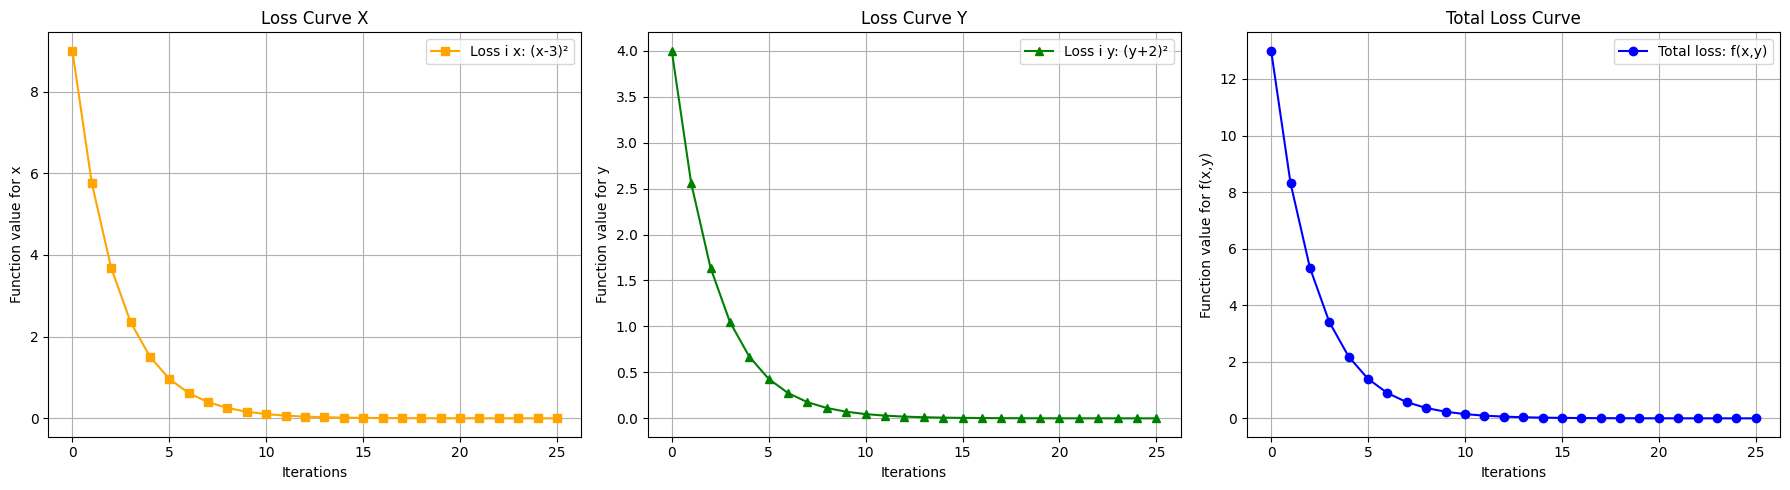

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(x, y):
    return (x - 3)**2 + (y + 2)**2

def f_x(x):
    return (x - 3)**2
def f_y(y):
    return (y + 2)**2

def gradient(x, y):
    df_dx = 2 * (x - 3)
    df_dy = 2 * (y + 2)
    return df_dx, df_dy

def gradient_descent(starting, learning_rate, iterations):
    x, y = starting

    loss_history = [f(x, y)]
    loss_x = [f_x(x)]
    loss_y = [f_y(y)]
    
    print(f"Start: x = {x:.4f}, y = {y:.4f}, total f(x, y) = {loss_history[0]:.4f}")
    
    for i in range(iterations):
        df_dx, df_dy = gradient(x, y)

        x -= learning_rate * df_dx
        y -= learning_rate * df_dy

        loss_history.append(f(x, y))
        loss_x.append(f_x(x))
        loss_y.append(f_y(y))
        
        print(f"Iterations {i+1}: x = {x:.4f}, y = {y:.4f}, total f(x, y) = {loss_history[-1]:.4f}")
    return x, y, loss_history, loss_x, loss_y

starting = (0, 0)
learning_rate = 0.1
iterations = 25  
min_x, min_y, loss_history, loss_x, loss_y = gradient_descent(starting, learning_rate, iterations)

print(f"\nMinimum: x = {min_x:.4f}, y = {min_y:.4f}")
print(f"Theoretical minimum: x = 3.0000, y = -2.0000")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

ax1.plot(range(iterations + 1), loss_x, marker='s', color='orange', label='Loss i x: (x-3)²')
ax1.set_xlabel('Iterations')
ax1.set_ylabel('Function value for x')
ax1.set_title('Loss Curve X')
ax1.legend()
ax1.grid(True)

ax2.plot(range(iterations + 1), loss_y, marker='^', color='green', label='Loss i y: (y+2)²')
ax2.set_xlabel('Iterations')
ax2.set_ylabel('Function value for y')
ax2.set_title('Loss Curve Y')
ax2.legend()
ax2.grid(True)

ax3.plot(range(iterations + 1), loss_history, marker='o', color='blue', label='Total loss: f(x,y)')
ax3.set_xlabel('Iterations')
ax3.set_ylabel('Function value for f(x,y)')
ax3.set_title('Total Loss Curve')
ax3.legend()
ax3.grid(True)

plt.tight_layout()
plt.show()

Question 2: Deep Learning for Image Classification



In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, f1_score


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)) 
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762))
])

trainset = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=train_transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=test_transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False, num_workers=2)


class CNN(nn.Module):
    def __init__(self, num_classes=100):
        super(CNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), 
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), 
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), 
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 2 * 2, 1024),
            nn.ReLU(),
            nn.Dropout(0.5), 
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = CNN().to(device)

weights_before = model.features[0].weight.data.cpu().clone()

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 15
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    history['train_loss'].append(running_loss / len(trainloader))
    history['train_acc'].append(100. * correct / total)
    
    model.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
    history['val_loss'].append(val_loss / len(testloader))
    history['val_acc'].append(100. * correct / total)
    
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {history['train_loss'][-1]:.4f}, Train Acc: {history['train_acc'][-1]:.2f}% - Val Loss: {history['val_loss'][-1]:.4f}, Val Acc: {history['val_acc'][-1]:.2f}%")

weights_after = model.features[0].weight.data.cpu().clone()

model.eval()
all_pred = []
all_targets = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        all_pred.extend(predicted.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

f1 = f1_score(all_targets, all_pred, average='macro')
accuracy = history['val_acc'][-1]

cm = confusion_matrix(all_targets, all_pred)
FP = cm.sum(axis=0) - np.diag(cm) 
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

print("\n--- Evaluation Metrics ---")
print(f"Accuracy: {accuracy:.2f}%")
print(f"F1-score (Macro): {f1:.4f}")
print(f"Total True Positives (TP): {TP.sum()}")
print(f"Total True Negatives (TN): {TN.sum()}")
print(f"Total False Positives (FP): {FP.sum()}")
print(f"Total False Negatives (FN): {FN.sum()}")

Files already downloaded and verified
Files already downloaded and verified
Epoch 1/15 - Train Loss: 3.9321, Train Acc: 8.85% - Val Loss: 3.4498, Val Acc: 16.55%
Epoch 2/15 - Train Loss: 3.3766, Train Acc: 16.97% - Val Loss: 3.0257, Val Acc: 23.39%
Epoch 3/15 - Train Loss: 3.0686, Train Acc: 22.76% - Val Loss: 2.6662, Val Acc: 30.28%
Epoch 4/15 - Train Loss: 2.8357, Train Acc: 26.83% - Val Loss: 2.4719, Val Acc: 34.70%
Epoch 5/15 - Train Loss: 2.6719, Train Acc: 30.43% - Val Loss: 2.3852, Val Acc: 36.83%
Epoch 6/15 - Train Loss: 2.5284, Train Acc: 33.40% - Val Loss: 2.2801, Val Acc: 39.08%
Epoch 7/15 - Train Loss: 2.4172, Train Acc: 35.78% - Val Loss: 2.1293, Val Acc: 42.73%
Epoch 8/15 - Train Loss: 2.3139, Train Acc: 38.41% - Val Loss: 1.9966, Val Acc: 45.43%
Epoch 9/15 - Train Loss: 2.2109, Train Acc: 40.49% - Val Loss: 1.9509, Val Acc: 46.89%
Epoch 10/15 - Train Loss: 2.1275, Train Acc: 42.44% - Val Loss: 1.9026, Val Acc: 47.70%
Epoch 11/15 - Train Loss: 2.0508, Train Acc: 44.10% - 

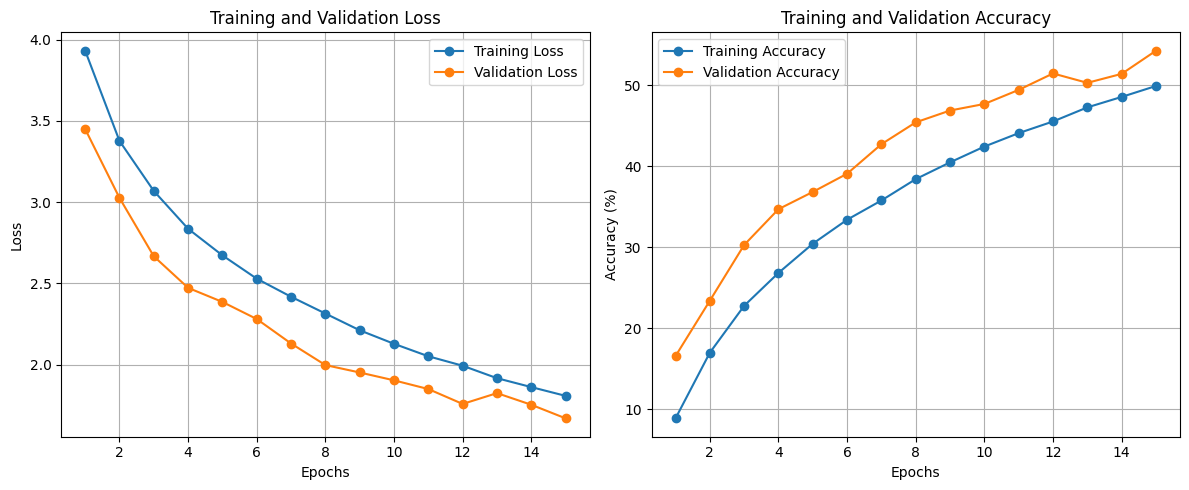

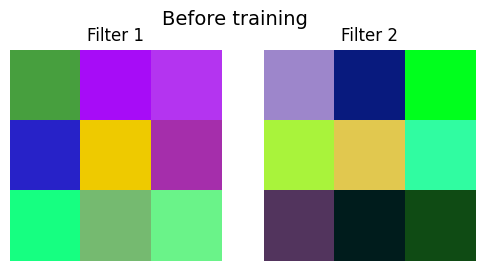

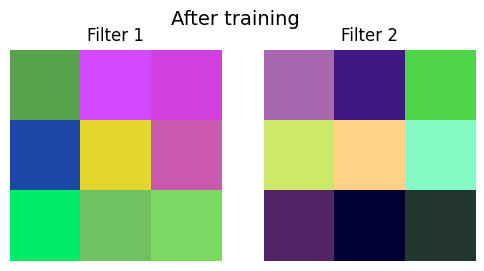

In [4]:
def plot_filters(weights, title):
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    fig.suptitle(title, fontsize=14)
    
    for i in range(2):
        filt = weights[i].numpy() 
        
        f_min, f_max = filt.min(), filt.max()
        filt_norm = (filt - f_min) / (f_max - f_min)
        filt_norm = filt_norm.transpose(1, 2, 0)

        axes[i].imshow(filt_norm)
        axes[i].set_title(f"Filter {i+1}")
        axes[i].axis('off') 
        
    plt.show()


epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

plot_filters(weights_before, "Before training")
plot_filters(weights_after, "After training")


Training and evaluating model: RESNET50
Epoch 1/50 - Train Loss: 2.6558,Train Acc: 34.04% - Val Loss: 2.0112,Val Acc: 46.22%
Epoch 2/50 - Train Loss: 1.8766,Train Acc: 49.14% - Val Loss: 1.7681,Val Acc: 51.78%
Epoch 3/50 - Train Loss: 1.6188,Train Acc: 55.10% - Val Loss: 1.7289,Val Acc: 54.05%
Epoch 4/50 - Train Loss: 1.4592,Train Acc: 58.75% - Val Loss: 1.5917,Val Acc: 57.10%
Epoch 5/50 - Train Loss: 1.3380,Train Acc: 61.26% - Val Loss: 1.5940,Val Acc: 57.48%
Epoch 6/50 - Train Loss: 1.2475,Train Acc: 63.86% - Val Loss: 1.5067,Val Acc: 59.58%
Epoch 7/50 - Train Loss: 1.1511,Train Acc: 66.34% - Val Loss: 1.5330,Val Acc: 59.52%
Epoch 8/50 - Train Loss: 1.0751,Train Acc: 68.15% - Val Loss: 1.5090,Val Acc: 60.38%
Epoch 9/50 - Train Loss: 1.0047,Train Acc: 69.84% - Val Loss: 1.5163,Val Acc: 60.89%
Epoch 10/50 - Train Loss: 0.9458,Train Acc: 71.41% - Val Loss: 1.5380,Val Acc: 60.85%
Epoch 11/50 - Train Loss: 0.8876,Train Acc: 73.15% - Val Loss: 1.5634,Val Acc: 60.87%
Epoch 12/50 - Train Lo

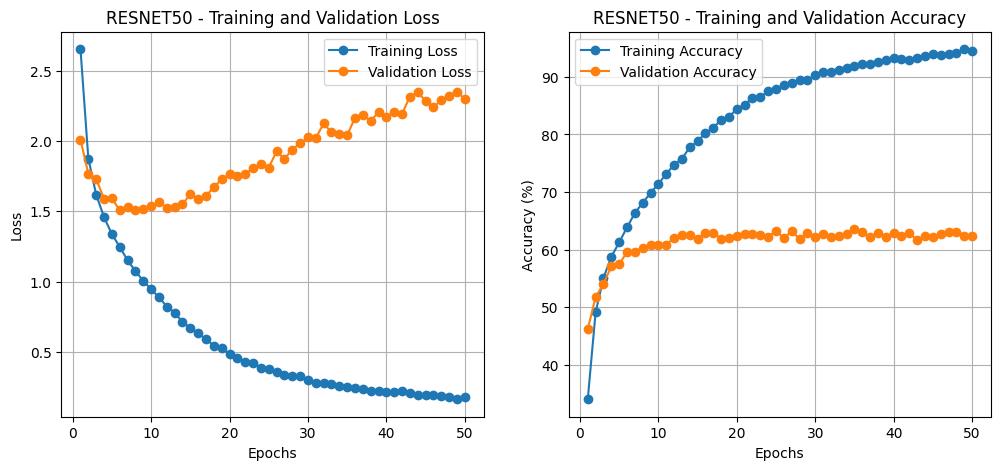

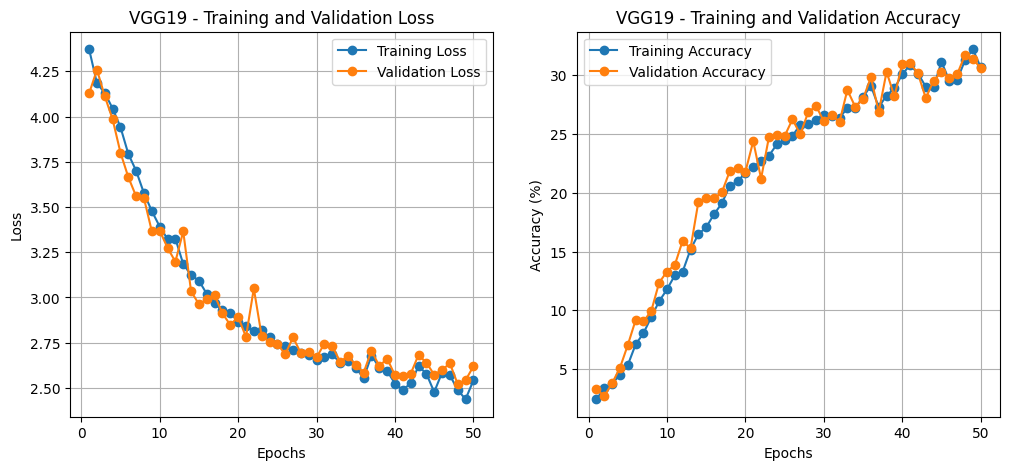

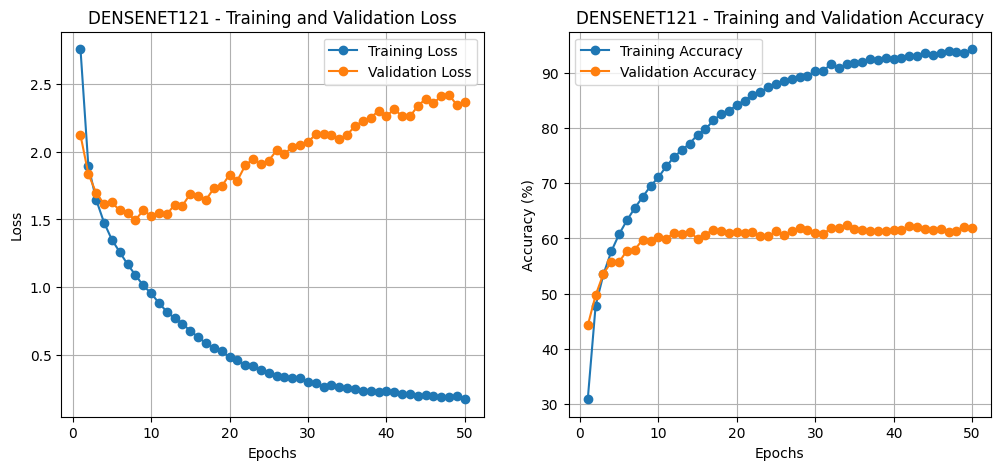

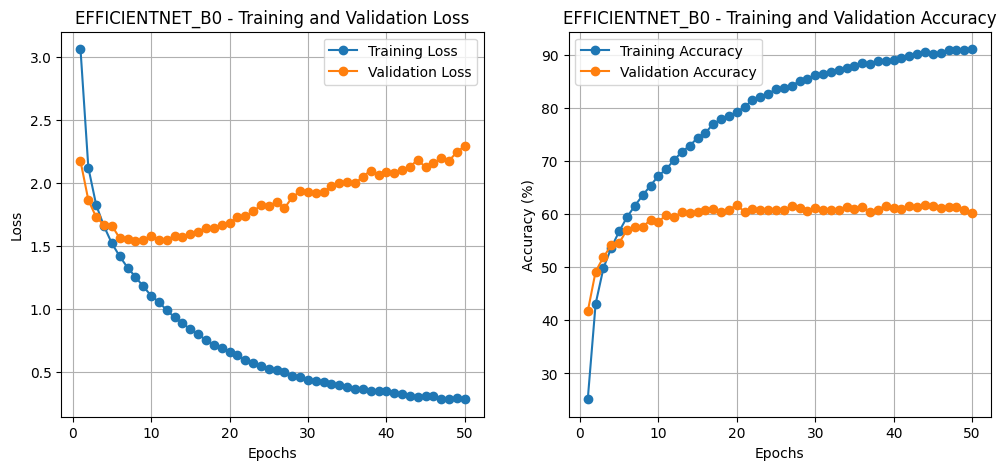

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as tv_models
import numpy as np
from sklearn.metrics import confusion_matrix, f1_score

def train_eval(model, trainloader, testloader, device, epochs=50):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        history['train_loss'].append(running_loss / len(trainloader))
        history['train_acc'].append(100. * correct / total)

        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in testloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        history['val_acc'].append(100. * correct / total)
        history['val_loss'].append(val_loss / len(testloader))

        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {history['train_loss'][-1]:.4f}," 
              f"Train Acc: {history['train_acc'][-1]:.2f}% - Val Loss: {history['val_loss'][-1]:.4f}," 
              f"Val Acc: {history['val_acc'][-1]:.2f}%")
    return model, history

model_dict = {
    "resnet50": tv_models.resnet50(weights=tv_models.ResNet50_Weights.DEFAULT),
    "vgg19": tv_models.vgg19(weights=tv_models.VGG19_Weights.DEFAULT),
    "densenet121": tv_models.densenet121(weights=tv_models.DenseNet121_Weights.DEFAULT),
    "efficientnet_b0": tv_models.efficientnet_b0(weights=tv_models.EfficientNet_B0_Weights.DEFAULT)
}

model_dict['resnet50'].fc = nn.Linear(model_dict['resnet50'].fc.in_features, 100)
model_dict['vgg19'].classifier[6] = nn.Linear(model_dict['vgg19'].classifier[6].in_features, 100)
model_dict['densenet121'].classifier = nn.Linear(model_dict['densenet121'].classifier.in_features, 100)
model_dict['efficientnet_b0'].classifier[1] = nn.Linear(model_dict['efficientnet_b0'].classifier[1].in_features, 100)

results = []
epochs = 50

for model_name, current_model in model_dict.items():
    print(f"\nTraining and evaluating model: {model_name.upper()}")
    current_model = current_model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(current_model.parameters(), lr=0.001)

    trained_model, history = train_eval(
        current_model, trainloader, testloader, 
        device, epochs=epochs)

    epochs_range = range(1, len(history['train_loss']) + 1)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Training Loss', marker='o')
    plt.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='o')
    plt.title(f'{model_name.upper()} - Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', marker='o')
    plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', marker='o')
    plt.title(f'{model_name.upper()} - Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True)

    trained_model.eval()
    all_pred = []
    all_targets = []

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = trained_model(inputs)
            _, predicted = torch.max(outputs, 1)
            all_pred.extend(predicted.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

    f1 = f1_score(all_targets, all_pred, average='macro')
    accuracy = history['val_acc'][-1]

    cm = confusion_matrix(all_targets, all_pred)
    FP = cm.sum(axis=0) - np.diag(cm)
    FN = cm.sum(axis=1) - np.diag(cm)
    TP = np.diag(cm)
    TN = cm.sum() - (FP + FN + TP)

    results.append({
        "Model": model_name.upper(), 
        "Accuracy": round(accuracy, 2),
        "F1-score": round(f1, 4),
        "TP": int(TP.sum()),
        "TN": int(TN.sum()),
        "FP": int(FP.sum()),
        "FN": int(FN.sum())
    })

print("\n --- Results Summary ---")
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


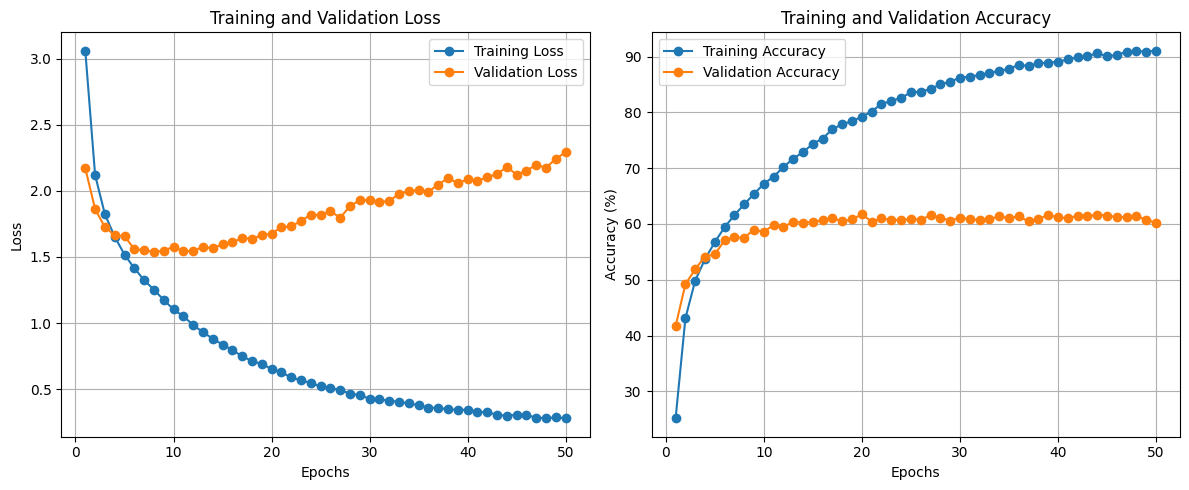

In [11]:
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights

resnet_model = resnet50(weights=ResNet50_Weights.DEFAULT)
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_ftrs, 100)
resnet_model = resnet_model.to(device)

optimizer_resnet = optim.Adam(resnet_model.parameters(), lr=0.0001)
weights_before = model.features[0].weight.data.cpu().clone()

criterion = nn.CrossEntropyLoss()
resNet_optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 50
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        resNet_optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        resNet_optimizer.step()
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    history['train_loss'].append(running_loss / len(trainloader))
    history['train_acc'].append(100. * correct / total)
    
    model.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
    history['val_loss'].append(val_loss / len(testloader))
    history['val_acc'].append(100. * correct / total)
    
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {history['train_loss'][-1]:.4f}, Train Acc: {history['train_acc'][-1]:.2f}% - Val Loss: {history['val_loss'][-1]:.4f}, Val Acc: {history['val_acc'][-1]:.2f}%")

weights_after = model.features[0].weight.data.cpu().clone()

model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

f1 = f1_score(all_targets, all_preds, average='macro')
accuracy = history['val_acc'][-1]

cm = confusion_matrix(all_targets, all_preds)
FP = cm.sum(axis=0) - np.diag(cm) 
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

print("\n--- Evaluation Metrics ---")
print(f"Accuracy: {accuracy:.2f}%")
print(f"F1-score (Macro): {f1:.4f}")
print(f"Total True Positives (TP): {TP.sum()}")
print(f"Total True Negatives (TN): {TN.sum()}")
print(f"Total False Positives (FP): {FP.sum()}")
print(f"Total False Negatives (FN): {FN.sum()}")